# Этап 1. EDA


## Загрузка данных из датасета `superstore_data.csv`

In [215]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# '.../superstore – корневая папка проекта
BASE_DIR = Path.cwd().parent
DATASET = 'superstore_data.csv'
DATASET_PATH = BASE_DIR / 'raw' / DATASET

# Читаем сырой csv
raw_df = pd.read_csv(DATASET_PATH, encoding='cp1252')
df_copy = raw_df.copy()  # Будем работать с копией данных

df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

## Аудит и преобразование данных в `df_copy`
Первичным анализом установлено, что в данных:
- Названия колонок в `CamelCase` –> Переведем в `snake_case` для удобства дальнейшей работы и интеграции в БД;
- Количество строк в `df_copy` = **9994**;
- Полные дубликаты колонок **отсутствуют**;
- Дубликаты колонок по `row_id` **отсутствуют**;
- `row_id` **уникальны**;

In [216]:
# Преобразуем названия колонок к нижнему регистру и убираем лишние символы
df_copy.columns = (
    df_copy.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^\w]", "", regex=True)
)
print('(ALTERED) Колонки преобразованы.')

columns_list = df_copy.columns.tolist()

# Общее число строк
print(f'Общее число строк: {len(df_copy)}')

# Проверка на полные дубликаты колонок
dups = df_copy.duplicated().sum()
if dups > 0:
    print(f'Найдено полных дубликатов колонок: {dubs}')
else:
    print(f'Полные дубликаты колонок отсутствуют.')

# Проверка на дубликаты по Row ID
row_id_dups = df_copy['row_id'].duplicated().sum()
if row_id_dups > 0:
    print(f'Найдены дубликаты по `row_id`: {row_id_dups}')
else:
    print('Дубликатов по `row_id` не найдено.')

# Проверка на уникальность Row ID
unique_row_id = df_copy['row_id'].is_unique
if unique_row_id is True:
    print('`row_id` уникальны.')
else:
    print('`row_id` не уникальны.')

(ALTERED) Колонки преобразованы.
Общее число строк: 9994
Полные дубликаты колонок отсутствуют.
Дубликатов по `row_id` не найдено.
`row_id` уникальны.


При проверке на дубли по суррогатному ключу `order_id` + `product_id` выявлено, что заказы `US-2014-150119`, `FUR-CH-10002965` – полные дубликаты, которые следует удалить. С остальными данными проблем не выявлено.

In [217]:
# Проверка на дубли по суррогатному ключу `order_id` + `product_id`
candidates = df_copy.loc[
    df_copy.duplicated(
        subset=["order_id", "product_id"],
        keep=False
    ),
    ["order_id", "product_id", "product_name", "quantity", "sales", "profit"]
].sort_values(["order_id", "product_id"])
# Инсайт: US-2014-150119, FUR-CH-10002965 (3405, 3406) – полные дубликаты, остальное в порядке, можно эти удалять

df_copy = df_copy.drop(index=3406)
df_copy.shape

(9993, 21)

`order_date` и `ship_date` – String, приводим к формату DateTime

In [218]:
# Приводим колонки дат из строк к DateTime
df_copy.order_date = pd.to_datetime(df_copy.order_date)
df_copy.ship_date = pd.to_datetime(df_copy.ship_date)

df_copy.head(5)

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,subcategory,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


`shipping_days` – новая колонка с количеством дней, затраченных на доставку

In [219]:
# Создаем новую колонку с информацией о днях доставки
df_copy['shipping_days'] = df_copy.ship_date - df_copy.order_date
df_copy['shipping_days'] = df_copy['shipping_days'].dt.days  # Приводим к int, чтобы не было записи вида `3 days`
df_copy.head(5)

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,region,product_id,category,subcategory,product_name,sales,quantity,discount,profit,shipping_days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7


При проверке на пропущенные значения в колонках – таковых не установлено.

In [220]:
# Проверка на пропущенные данные в колонках
df_copy.isna().sum()

row_id           0
order_id         0
order_date       0
ship_date        0
ship_mode        0
customer_id      0
customer_name    0
segment          0
country          0
city             0
state            0
postal_code      0
region           0
product_id       0
category         0
subcategory      0
product_name     0
sales            0
quantity         0
discount         0
profit           0
shipping_days    0
dtype: int64

## Бизнес-метрики

In [221]:
summary = {
    'total_sales': df_copy['sales'].sum(),
    'total_profit': df_copy['profit'].sum(),
    'profit_margin': df_copy['profit'].sum() / df_copy['sales'].sum(),
    'orders': df_copy['order_id'].nunique(),
    'customers': df_copy['customer_id'].nunique(),
}
summary

{'total_sales': np.float64(2296919.4883000003),
 'total_profit': np.float64(286409.0805),
 'profit_margin': np.float64(0.12469269469779175),
 'orders': 5009,
 'customers': 793}

## Анализ по измерениям

### Прибыль по `category`, `region`, `segment`, `ship_mode`

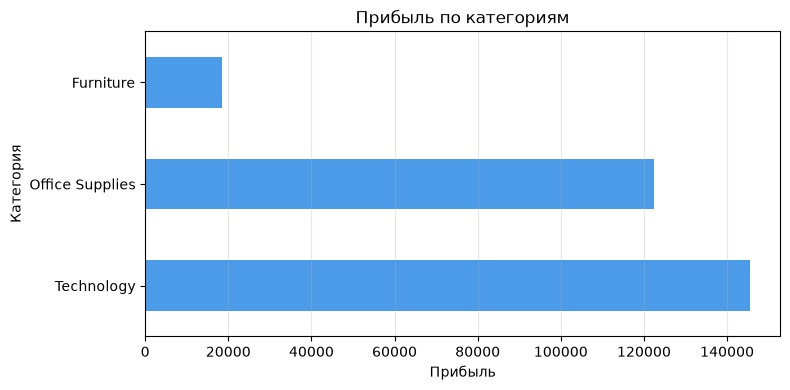

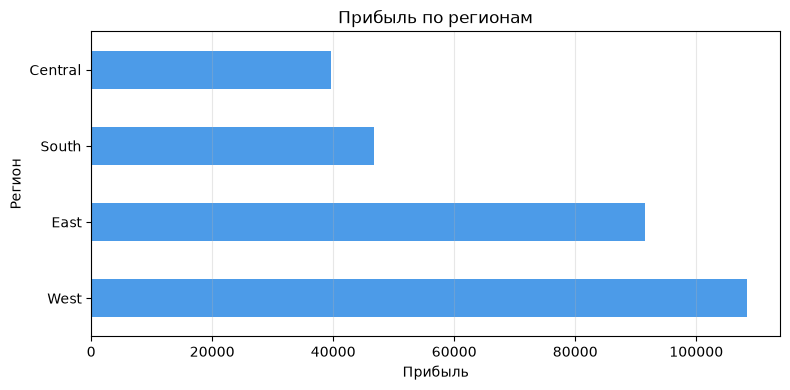

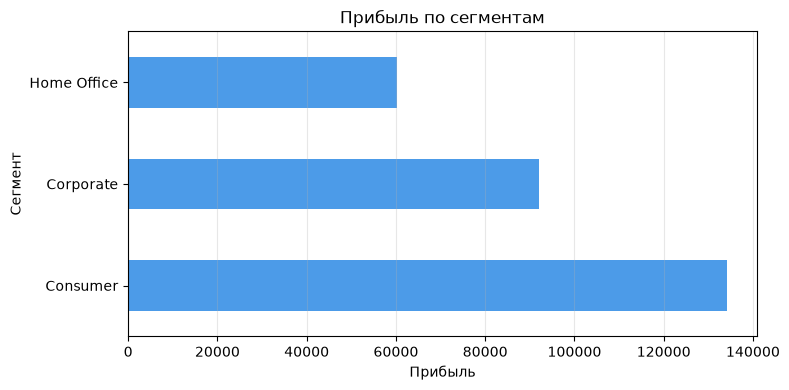

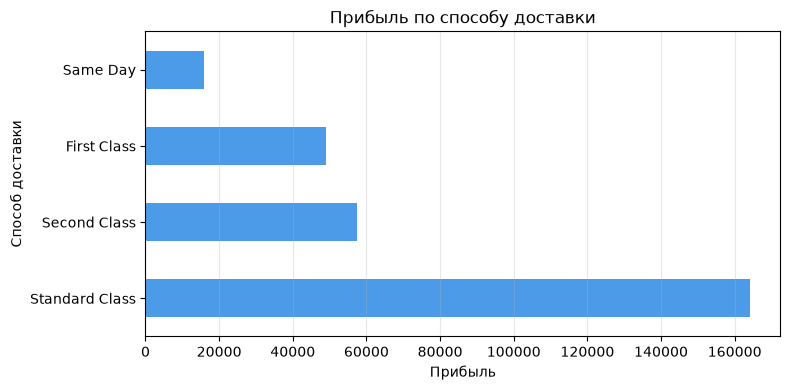

In [227]:
# Группировка прибыли по `category`
category_profit = (
    df_copy
    .groupby('category', as_index=False)
    .agg(total_profit=('profit', 'sum'))
    .sort_values('total_profit', ascending=False)
).plot.barh(
    x='category',
    y='total_profit',
    legend=False,
    color='#4C9BE8',
    title='Прибыль по категориям',
    figsize=(8, 4)
)
plt.xlabel('Прибыль')
plt.ylabel('Категория')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Группировка прибыли по `region`
category_profit = (
    df_copy
    .groupby('region', as_index=False)
    .agg(total_profit=('profit', 'sum'))
    .sort_values('total_profit', ascending=False)
).plot.barh(
    x='region',
    y='total_profit',
    legend=False,
    color='#4C9BE8',
    title='Прибыль по регионам',
    figsize=(8, 4)
)
plt.xlabel('Прибыль')
plt.ylabel('Регион')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Группировка прибыли по `segment`
category_profit = (
    df_copy
    .groupby('segment', as_index=False)
    .agg(total_profit=('profit', 'sum'))
    .sort_values('total_profit', ascending=False)
).plot.barh(
    x='segment',
    y='total_profit',
    legend=False,
    color='#4C9BE8',
    title='Прибыль по сегментам',
    figsize=(8, 4)
)
plt.xlabel('Прибыль')
plt.ylabel('Сегмент')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Группировка прибыли по `ship_mode`
category_profit = (
    df_copy
    .groupby('ship_mode', as_index=False)
    .agg(total_profit=('profit', 'sum'))
    .sort_values('total_profit', ascending=False)
).plot.barh(
    x='ship_mode',
    y='total_profit',
    legend=False,
    color='#4C9BE8',
    title='Прибыль по способу доставки',
    figsize=(8, 4)
)
plt.xlabel('Прибыль')
plt.ylabel('Способ доставки')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Определение сезонности

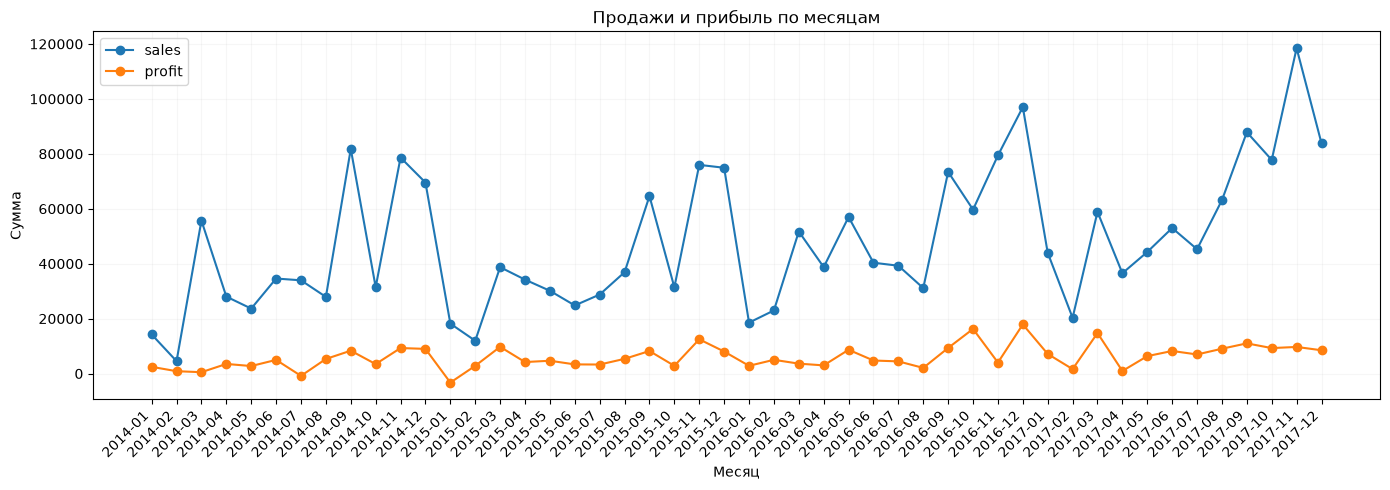

In [241]:
monthly = (
    df_copy
    .assign(order_month=df_copy['order_date'].dt.to_period('M'))
    .groupby('order_month', as_index=False)
    .agg(
        sales=('sales', 'sum'),
        profit=('profit', 'sum'),
    )
)

monthly['order_month'] = monthly['order_month'].astype(str)

ax = monthly.plot(
    x='order_month',
    y=['sales', 'profit'],
    kind='line',
    marker='o',
    figsize=(14, 5),
    title='Продажи и прибыль по месяцам',
)

ax.set_xlabel('Месяц')
ax.set_ylabel('Сумма')
ax.grid(alpha=0.1)

ax.set_xticks(range(len(monthly)))
ax.set_xticklabels(
    monthly['order_month'],
    rotation=45,
    ha='right',
)

plt.tight_layout()
plt.show()

In [ ]:
# Скидка против прибыли
ax = df_copy.plot.scatter(
    x='discount',
    y='profit',
    alpha=0.4,
    figsize=(9, 5),
    title='Скидка и прибыль',
)

ax.axhline(0, color='black', linewidth=1)
ax.set_xlabel('Discount')
ax.set_ylabel('Profit')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ax = df_copy["shipping_days"].plot.hist(
    bins=range(
        int(df_copy["shipping_days"].min()),
        int(df_copy["shipping_days"].max()) + 2,
    ),
    figsize=(9, 5),
    color="#4C9BE8",
    title="Распределение срока доставки",
)

ax.set_xlabel("Дней до отправки")
ax.set_ylabel("Количество строк")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()